# 09 · Quantization: smaller, faster models

A 70B model in bf16 is 140 GB (two H100s); in INT4 it is 35 GB (one). Decode is memory-bandwidth-bound, so reading half the bytes per token ≈ twice the tokens per second. Quantization is the best cost/benefit optimization in inference.

**What you will learn**
- Symmetric absmax quantization; why **block-wise scales** are mandatory (outliers)
- **NF4** (QLoRA): non-uniform levels at Gaussian quantiles
- A `QuantizedLinear` that stores ints + scales and dequantizes on the fly (what bitsandbytes does)
- Evaluation: weight error → perplexity degradation → task accuracy, as a function of bits and block size

**Source:** `llmsuite/quant.py`.

In [1]:
import os, sys, math, time, random, copy
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llmsuite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # climb from notebooks/<topic>/ up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llmsuite` works from any notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llmsuite.utils import seed_everything, get_device, count_params, human
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


## 1. Absmax quantization and the outlier problem
$$q = \text{round}(x/s),\quad s = \max|x| / (2^{b-1}-1)$$
A single large weight sets the scale for everything it shares a scale with. Per-tensor → catastrophic; per-row → better; per-block (32–128) → the damage is confined to one block.

In [2]:
from llmsuite.quant import quantize_absmax, quantize_nf4, quantization_error
W = torch.randn(256, 512) * 0.02
W[3, 7], W[100, 200] = 1.5, -1.2                   # two outliers, like the ones real LLM weights have

for bits in (8, 4):
    print(f"--- {bits} bits ---")
    for name, kw in [("per tensor", {}), ("per row", {"per_row": True}), ("block 128", {"block": 128}), ("block 32", {"block": 32})]:
        _, s, W_hat = quantize_absmax(W, bits, **kw)
        print(f"  {name:11s} rel. RMS error {100*quantization_error(W, W_hat):6.2f}%   scale overhead {s.numel()*16/W.numel():.3f} bits/weight")

--- 8 bits ---
  per tensor  rel. RMS error  16.42%   scale overhead 0.000 bits/weight
  per row     rel. RMS error   1.48%   scale overhead 0.031 bits/weight
  block 128   rel. RMS error   0.92%   scale overhead 0.125 bits/weight
  block 32    rel. RMS error   0.61%   scale overhead 0.500 bits/weight
--- 4 bits ---
  per tensor  rel. RMS error  96.67%   scale overhead 0.000 bits/weight
  per row     rel. RMS error  15.49%   scale overhead 0.031 bits/weight
  block 128   rel. RMS error  12.05%   scale overhead 0.125 bits/weight
  block 32    rel. RMS error   9.62%   scale overhead 0.500 bits/weight


## 2. NF4: put the 16 levels where the weights are
Weights are roughly Gaussian: many near zero, few far away. INT4's 16 equally-spaced levels waste resolution in the tails; NF4 places them at Gaussian quantiles so each level is used about equally.

NF4 levels: [-1.0, -0.766, -0.607, -0.48, -0.37, -0.27, -0.177, -0.088, 0.0, 0.099, 0.2, 0.307, 0.423, 0.557, 0.722, 0.963]
INT4 block 64: 10.77% | NF4 block 64: 9.02% relative RMS error


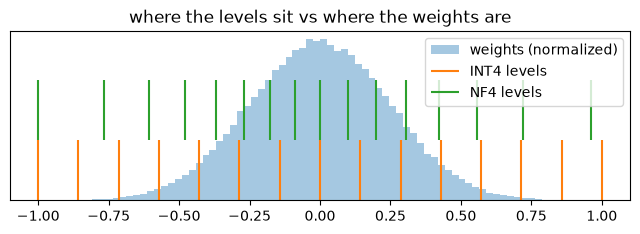

In [3]:
from llmsuite.quant import nf4_levels
import matplotlib.pyplot as plt
lv = nf4_levels()
print("NF4 levels:", [round(v, 3) for v in lv.tolist()])
_, _, w_int4 = quantize_absmax(W, 4, block=64)
_, _, w_nf4 = quantize_nf4(W, block=64)
print(f"INT4 block 64: {100*quantization_error(W, w_int4):.2f}% | NF4 block 64: {100*quantization_error(W, w_nf4):.2f}% relative RMS error")

fig, ax = plt.subplots(figsize=(8, 2.2))
ax.hist((W[W.abs() < 0.08] / 0.08).flatten().numpy(), bins=80, density=True, alpha=.4, label="weights (normalized)")
ax.vlines(torch.linspace(-1, 1, 15), 0, 0.6, colors="C1", label="INT4 levels"); ax.vlines(lv, 0.6, 1.2, colors="C2", label="NF4 levels")
ax.legend(loc="upper right"); ax.set_yticks([]); ax.set_title("where the levels sit vs where the weights are"); plt.show()

## 3. Quantize a trained model and measure what matters
Weight error is a proxy. The real questions: how much does the **model's output** change, and does quality drop, vs memory saved? We train a small LM, quantize it at several settings and measure three things on held-out data:

| metric | what it measures | why |
|---|---|---|
| **KL(fp ‖ quant)** | how far the quantized next-token distribution is from the original | the most sensitive signal; `llama.cpp` reports exactly this for its GGUF quants |
| **top-1 agreement** | % of positions where both models predict the same token | intuitive "does it still say the same thing?" |
| **perplexity delta** | change in held-out perplexity | cheap and standard, but *insensitive* on easy data — a small change can even be noise |

In [4]:
from llmsuite.model import ModelConfig, TransformerLM
from llmsuite.data import synthetic_structured_corpus, train_val_split, get_batch
from llmsuite.training import TrainConfig, train_lm
from llmsuite.evaluation import perplexity
from llmsuite.quant import quantize_model, model_memory_bytes, QuantizedLinear

data = synthetic_structured_corpus(n_tokens=150_000, vocab=512, n_words=80)
train_data, val_data = train_val_split(data)
seed_everything(0)
model = TransformerLM(ModelConfig(vocab_size=512, d_model=192, n_layers=4, n_heads=6, n_kv_heads=2)).to(device)
train_lm(model, train_data, val_data, TrainConfig(steps=400, batch_size=32, block_size=64, max_lr=3e-3, warmup=40, eval_every=400, log=False), device)
base_ppl = perplexity(model, val_data, block_size=64, n_batches=30, device=device)
base_mem = model_memory_bytes(model)
print(f"fp16-equivalent: {base_mem/1024:.0f} KB | val ppl {base_ppl:.3f}")

torch.manual_seed(123)
xb, _ = get_batch(val_data, 64, 64, device)                      # one fixed held-out batch, so every comparison sees the same inputs
model.eval()
with torch.no_grad():
    ref_logp = model(xb)[0].log_softmax(-1)

def output_drift(qm):
    with torch.no_grad():
        q_logp = qm(xb)[0].log_softmax(-1)
    kl = (ref_logp.exp() * (ref_logp - q_logp)).sum(-1).mean().item()            # KL(fp || quant) in nats per token
    agree = (ref_logp.argmax(-1) == q_logp.argmax(-1)).float().mean().item()
    return kl, agree

rows = []
for bits, block, scheme in [(8, 64, "absmax"), (4, 128, "absmax"), (4, 32, "absmax"), (4, 64, "nf4"), (3, 32, "absmax"), (2, 32, "absmax")]:
    qm = quantize_model(copy.deepcopy(model), bits=bits, block=block, scheme=scheme).to(device).eval()
    ppl = perplexity(qm, val_data, block_size=64, n_batches=30, device=device)
    mem = model_memory_bytes(qm)
    kl, agree = output_drift(qm)
    rows.append((f"{scheme} {bits}b/blk{block}", ppl, mem, kl, agree))
    print(f"{scheme:6s} {bits} bits block {block:3d}: KL {kl:.5f} | top-1 agree {100*agree:5.1f}% | ppl {ppl:7.3f} ({100*(ppl/base_ppl-1):+5.2f}%) | memory {mem/1024:5.0f} KB ({mem/base_mem:.2f}x)")

fp16-equivalent: 3267 KB | val ppl 2.923


absmax 8 bits block  64: KL 0.00000 | top-1 agree  99.9% | ppl   2.921 (-0.07%) | memory  1779 KB (0.54x)


absmax 4 bits block 128: KL 0.00011 | top-1 agree  97.9% | ppl   2.916 (-0.23%) | memory   987 KB (0.30x)


absmax 4 bits block  32: KL 0.00007 | top-1 agree  98.2% | ppl   2.933 (+0.33%) | memory  1059 KB (0.32x)


nf4    4 bits block  64: KL 0.00005 | top-1 agree  98.6% | ppl   2.928 (+0.16%) | memory  1011 KB (0.31x)


absmax 3 bits block  32: KL 0.00041 | top-1 agree  94.8% | ppl   2.932 (+0.29%) | memory   867 KB (0.27x)


absmax 2 bits block  32: KL 0.01350 | top-1 agree  87.9% | ppl   2.959 (+1.23%) | memory   675 KB (0.21x)


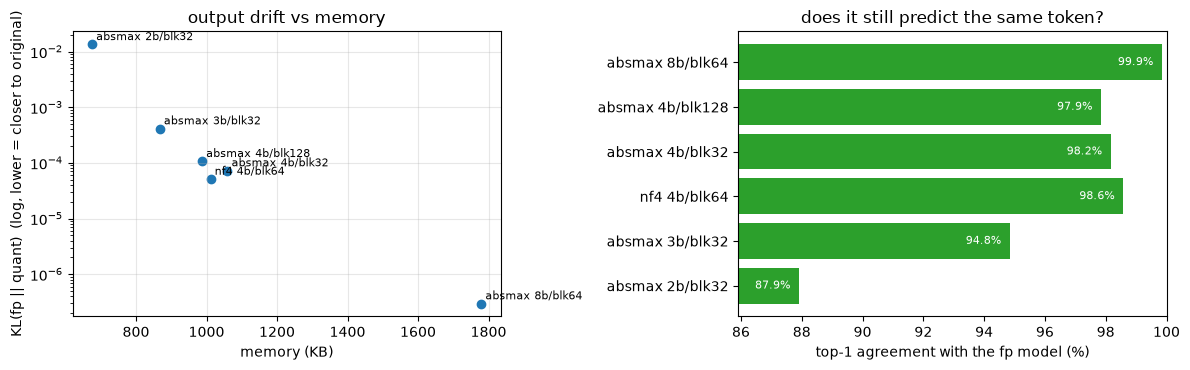

In [5]:
names, ppls, mems, kls, agrees = zip(*rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter([m / 1024 for m in mems], kls)
for n, m, k in zip(names, mems, kls): ax[0].annotate(n, (m / 1024, k), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[0].set_yscale("log"); ax[0].set_xlabel("memory (KB)"); ax[0].set_ylabel("KL(fp || quant)  (log, lower = closer to original)")
ax[0].set_title("output drift vs memory"); ax[0].grid(alpha=.3)
ax[1].barh(names, [100 * a for a in agrees], color="tab:green"); ax[1].set_xlim(min(100 * a for a in agrees) - 2, 100)
for i, a in enumerate(agrees): ax[1].text(100 * a - 0.3, i, f"{100*a:.1f}%", va="center", ha="right", color="white", fontsize=8)
ax[1].invert_yaxis(); ax[1].set_xlabel("top-1 agreement with the fp model (%)"); ax[1].set_title("does it still predict the same token?")
plt.tight_layout(); plt.show()

**Reading the results.** The KL axis is logarithmic: every bit removed multiplies the output drift, and 2-bit is far from the original model even when perplexity barely moves. On this easy synthetic language the model is very confident, so perplexity is a blunt instrument here — on real models at ≤3 bits perplexity does degrade clearly. At the same 4 bits, smaller blocks (more scales) and NF4 (levels matched to the weight distribution) are closer to the original than large absmax blocks.

## 4. Evaluation protocol for quantization in practice

1. **Perplexity delta** on held-out text (cheap, sensitive): INT8 ≈ 0 %, W4 with groups ≈ +1–3 % for ≥7B models, <3B models degrade more; below 4 bits quality drops fast.
2. **Task accuracy** on *your* eval set — perplexity can hide regressions on specific capabilities (math, code, long context).
3. **Speed and memory** on the target hardware with the real kernel (AWQ/GPTQ/Marlin for W4A16, FP8 on Hopper, GGUF on CPU).
4. Also quantize the **KV-cache** (fp8/int8) — it is often the larger memory consumer at long context.

Tooling: `AutoAWQ` / `GPTQModel` → vLLM; `llama.cpp` for GGUF; `bitsandbytes` NF4 for QLoRA training; `torchao` for PyTorch-native quantization.

**Next:** `10_rag.ipynb`.